# Day 1 · Notebook 5 — COLMAP step by step (command line)

COLMAP (Schönberger & Frahm, CVPR 2016) is the standard **Structure-from-Motion** tool. It combines everything from Notebooks 1–3, over many images, offline:

```
images ──► feature_extractor ──► exhaustive_matcher ──► mapper ──► sparse model
            (SIFT)                (match + RANSAC        (incremental SfM:        cameras / images / points3D
                                   geometric check)       init pair, PnP, triangulate, bundle adjustment)
```

We run each stage **separately from the CLI** and look at what it wrote, so nothing is a black box.

Data: the 10 Sacre Coeur photos (different tourists, different cameras, so no calibration is known).

### Install COLMAP (conda-forge)

* **Colab**: the next cell installs `micromamba` and puts COLMAP in its own env at `/opt/colmap_env` (about 2 min, no kernel restart).
* **Laptop**: `conda install -c conda-forge colmap` (CUDA build, so dense reconstruction also works), then skip the next cell.

In [ ]:
# Colab only (skip on the laptop if `colmap -h` already works)
!curl -Ls https://github.com/mamba-org/micromamba-releases/releases/latest/download/micromamba-linux-64 -o /usr/local/bin/micromamba && chmod +x /usr/local/bin/micromamba
!micromamba create -y -q -p /opt/colmap_env -c conda-forge colmap > /dev/null
!/opt/colmap_env/bin/colmap -h | head -n 2

In [11]:
import os, re, shutil, sqlite3, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go

os.environ["QT_QPA_PLATFORM"] = "offscreen"          # no display needed
COLMAP = shutil.which("colmap") or "/opt/colmap_env/bin/colmap"
print("using", COLMAP)

DATA = next((p for p in [Path("data"), Path("../data")] if p.exists()), Path("data"))
if not (DATA / "sacre_coeur/mapping").exists():
    subprocess.run("git clone -q --depth 1 https://github.com/cvg/Hierarchical-Localization /tmp/hloc_repo",
                   shell=True, check=True)
    shutil.copytree("/tmp/hloc_repo/datasets/sacre_coeur/mapping", DATA / "sacre_coeur/mapping")

WS = Path("colmap_ws")                                 # workspace
shutil.rmtree(WS, ignore_errors=True)
shutil.copytree(DATA / "sacre_coeur/mapping", WS / "images")
DB, IMAGES, SPARSE, SNAP = WS / "database.db", WS / "images", WS / "sparse", WS / "snapshots"
SPARSE.mkdir(); SNAP.mkdir()
print(len(list(IMAGES.iterdir())), "images in", IMAGES)

using /usr/local/bin/colmap
10 images in colmap_ws/images


## Step 1 · `feature_extractor`

For every image: read EXIF (if any), create a **camera** with a guess for the focal length ($f \approx 1.2 \cdot \max(W,H)$ when EXIF is missing), detect **SIFT** keypoints + descriptors, and store everything in an SQLite **database**.

(`--FeatureExtraction.use_gpu 0`: CPU SIFT. On a CUDA machine you can drop it. Older COLMAP releases (e.g. 3.11) call these `--SiftExtraction.use_gpu` / `--SiftExtraction.max_image_size` (and `--SiftMatching.use_gpu` for the matcher).)

In [12]:
!{COLMAP} feature_extractor --database_path {DB} --image_path {IMAGES} --ImageReader.camera_model SIMPLE_RADIAL --FeatureExtraction.use_gpu 0 --FeatureExtraction.max_image_size 1600 2>&1 | grep -E "Name|Focal|Features"

I1022 16:43:20.737411 1127202 feature_extraction.cc:283]   Name:            03903474_1471484089.jpg
I1022 16:43:20.737430 1127202 feature_extraction.cc:298]   Focal Length:    1296.00px
I1022 16:43:20.737453 1127202 feature_extraction.cc:302]   Features:        7266 (SIFT)
I1022 16:43:21.479507 1127202 feature_extraction.cc:283]   Name:            32809961_8274055477.jpg
I1022 16:43:21.479524 1127202 feature_extraction.cc:298]   Focal Length:    1280.40px
I1022 16:43:21.479535 1127202 feature_extraction.cc:302]   Features:        7571 (SIFT)
I1022 16:43:21.551458 1127202 feature_extraction.cc:283]   Name:            17295357_9106075285.jpg
I1022 16:43:21.551486 1127202 feature_extraction.cc:298]   Focal Length:    1215.60px
I1022 16:43:21.551498 1127202 feature_extraction.cc:302]   Features:        10502 (SIFT)
I1022 16:43:21.602313 1127202 feature_extraction.cc:283]   Name:            44120379_8371960244.jpg
I1022 16:43:21.602339 1127202 feature_extraction.cc:298]   Focal Length:    1

### What's inside `database.db`?

It's a plain SQLite file. Tables: `cameras`, `images`, `keypoints` (N×6: x, y + affine shape), `descriptors` (N×128 uint8), `matches`, `two_view_geometries`.

['rigs', 'sqlite_sequence', 'rig_sensors', 'cameras', 'frames', 'frame_data', 'images', 'pose_priors', 'keypoints', 'descriptors', 'matches', 'two_view_geometries']
image  1 03903474_1471484089.jpg        7266 keypoints  (6 values each)
image  2 32809961_8274055477.jpg        7571 keypoints  (6 values each)
image  3 17295357_9106075285.jpg       10502 keypoints  (6 values each)
image  4 44120379_8371960244.jpg        6994 keypoints  (6 values each)
image  5 10265353_3838484249.jpg        9728 keypoints  (6 values each)
image  6 02928139_3448003521.jpg       10384 keypoints  (6 values each)
image  7 60584745_2207571072.jpg       10225 keypoints  (6 values each)
image  8 51091044_3486849416.jpg       13144 keypoints  (6 values each)
image  9 71295362_4051449754.jpg        7796 keypoints  (6 values each)
image 10 93341989_396310999.jpg         6715 keypoints  (6 values each)


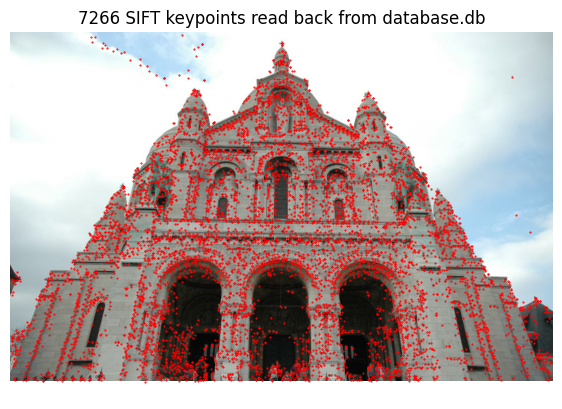

In [13]:
con = sqlite3.connect(DB)
print([r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table'")])
names = dict(con.execute("SELECT image_id, name FROM images"))
for image_id, rows, cols in con.execute("SELECT image_id, rows, cols FROM keypoints"):
    print(f"image {image_id:2d} {names[image_id]:28s} {rows:6d} keypoints  ({cols} values each)")

# decode the keypoint blob of image 1 and draw it
img_id = 1
rows, cols, blob = con.execute("SELECT rows, cols, data FROM keypoints WHERE image_id=?", (img_id,)).fetchone()
kps = np.frombuffer(blob, np.float32).reshape(rows, cols)
img = plt.imread(IMAGES / names[img_id])
plt.figure(figsize=(7, 8)); plt.imshow(img); plt.plot(kps[:, 0], kps[:, 1], "r.", ms=1)
plt.title(f"{rows} SIFT keypoints read back from database.db"); plt.axis("off"); plt.show()

## Step 2 · `exhaustive_matcher`

Match every pair of images ($\binom{10}{2} = 45$ pairs). For each pair COLMAP stores:

* `matches`: raw descriptor matches
* `two_view_geometries`: matches that survive **RANSAC** with $E$, $F$ or $H$ (Notebook 1!)

For thousands of images you'd use `vocab_tree_matcher` or `sequential_matcher` instead. (Image retrieval: Day 2.)

In [14]:
!{COLMAP} exhaustive_matcher --database_path {DB} --FeatureMatching.use_gpu 0 2>&1 | tail -n 2

I1022 16:43:33.952347 1127354 feature_matching.cc:217] in 4.525s
I1022 16:43:33.952373 1127354 timer.cc:90] Elapsed time: 0.075 [minutes]


geometry type per verified pair: {'uncalibrated (F)': 40, 'undefined (too few inliers)': 1, 'planar/panoramic': 4}


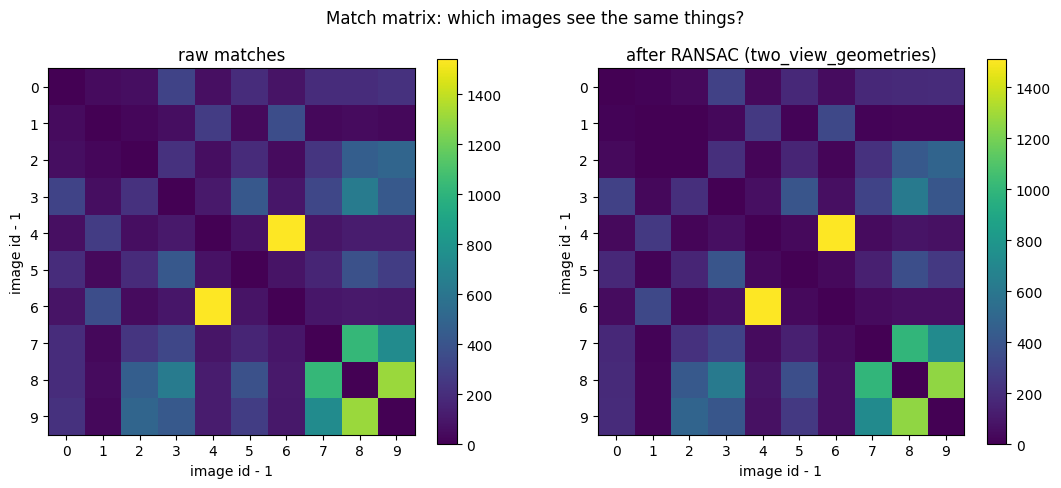

In [15]:
MAX_ID = 2147483647
def pair_to_ids(pair_id):                      # COLMAP encodes (i, j) as i * MAX_ID + j
    return pair_id // MAX_ID, pair_id % MAX_ID

n = len(names)
raw, verified = np.zeros((n, n)), np.zeros((n, n))
for pid, r in con.execute("SELECT pair_id, rows FROM matches"):
    i, j = pair_to_ids(pid); raw[i - 1, j - 1] = raw[j - 1, i - 1] = r
config_name = {0: "undefined (too few inliers)", 1: "degenerate", 2: "calibrated (E)",
               3: "uncalibrated (F)", 4: "planar (H)", 5: "panoramic", 6: "planar/panoramic"}
configs = {}
for pid, r, cfg in con.execute("SELECT pair_id, rows, config FROM two_view_geometries"):
    i, j = pair_to_ids(pid); verified[i - 1, j - 1] = verified[j - 1, i - 1] = r
    configs[config_name.get(cfg, str(cfg))] = configs.get(config_name.get(cfg, str(cfg)), 0) + 1
print("geometry type per verified pair:", configs)

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, M, t in [(axs[0], raw, "raw matches"), (axs[1], verified, "after RANSAC (two_view_geometries)")]:
    im = ax.imshow(M, cmap="viridis"); ax.set_title(t); plt.colorbar(im, ax=ax)
    ax.set_xticks(range(n)); ax.set_yticks(range(n)); ax.set_xlabel("image id - 1"); ax.set_ylabel("image id - 1")
plt.suptitle("Match matrix: which images see the same things?"); plt.show()

## Step 3 · `mapper`: incremental SfM

1. **Initialise** from a pair with many verified matches and a wide baseline: $E$ → $(R,t)$ → triangulate
2. **Register** the next image that sees the most existing 3D points: **PnP + RANSAC** (Day 2)
3. **Triangulate** new points seen by the new image
4. **Bundle adjustment** (Notebook 3), local after each image and global every so often:
$$ \min_{\{K_c, R_i, \mathbf{t}_i\},\{\mathbf{X}_j\}} \sum_{i,j} \rho\big(\|\pi(K_c, R_i, \mathbf{t}_i, \mathbf{X}_j) - \mathbf{x}_{ij}\|^2\big) $$
5. Filter outliers, repeat 2–5 until no image can be added

`--Mapper.snapshot_frames_freq 1` saves the model after every newly registered image, so we can watch it grow.

In [16]:
!{COLMAP} mapper --database_path {DB} --image_path {IMAGES} --output_path {SPARSE} --Mapper.snapshot_path {SNAP} --Mapper.snapshot_frames_freq 1 > {WS}/mapper.log 2>&1
log = (WS / "mapper.log").read_text()
tried = re.findall(r"initial image pair #(\d+) and #(\d+)", log)
print("Initial pairs tried (bad ones are discarded):", tried)
final_run = log.split("initial image pair")[-1]          # log of the attempt that succeeded
print("Images registered after that (PnP):", re.findall(r"Registering image #(\d+)", final_run))
print("Models written:", sorted(p.name for p in SPARSE.iterdir()))

Initial pairs tried (bad ones are discarded): [('7', '9'), ('4', '5'), ('5', '2')]
Images registered after that (PnP): ['7', '4', '10', '9', '6', '8', '3', '1', '4']
Models written: ['0']


In [17]:
# There can be several models if the images split into groups; take the biggest one.
def n_registered(model_dir):
    out = subprocess.run([COLMAP, "model_analyzer", "--path", str(model_dir)], capture_output=True, text=True)
    m = re.search(r"Registered images: (\d+)", out.stdout + out.stderr)
    return int(m.group(1)) if m else 0

MODEL = max(SPARSE.iterdir(), key=n_registered)
print("biggest model:", MODEL)
!{COLMAP} model_analyzer --path {MODEL} 2>&1 | grep -E "Cameras|Registered images|Points|Observations|track length|reprojection"

biggest model: colmap_ws/sparse/0
I1022 16:43:38.511590 1127574 model.cc:436] Cameras: 10
I1022 16:43:38.511605 1127574 model.cc:441] Registered images: 10
I1022 16:43:38.511608 1127574 model.cc:443] Points: 1414
I1022 16:43:38.511611 1127574 model.cc:444] Observations: 5578
I1022 16:43:38.511615 1127574 model.cc:446] Mean track length: 3.944837
I1022 16:43:38.511627 1127574 model.cc:451] Mean reprojection error: 0.340859px


## Step 4 · `model_converter`: look at the output files

Convert the binary model to text. The three important files:

| file | one line per | contents |
|---|---|---|
| `cameras.txt` | camera | model, width, height, intrinsics (e.g. `SIMPLE_RADIAL`: $f, c_x, c_y, k$) |
| `images.txt` | image | pose as quaternion $q$ + translation $\mathbf{t}$ (**cam-from-world**), then its 2D points |
| `points3D.txt` | 3D point | $X, Y, Z$, colour, mean reprojection error, **track** (which images see it) |

The camera centre in the world is $\mathbf{C} = -R(q)^\top \mathbf{t}$.

In [18]:
TXT = WS / "sparse_txt"; TXT.mkdir(exist_ok=True)
!{COLMAP} model_converter --input_path {MODEL} --output_path {TXT} --output_type TXT
for f in ["cameras.txt", "images.txt", "points3D.txt"]:
    print(f"----- {f} -----")
    for line in (TXT / f).read_text().splitlines()[:6]:
        print(line[:150])

----- cameras.txt -----
# Camera list with one line of data per camera:
#   CAMERA_ID, MODEL, WIDTH, HEIGHT, PARAMS[]
# Number of cameras: 10
1 SIMPLE_RADIAL 780 1063 1274.7011454147225 390 531.5 0.011548893479341295
2 SIMPLE_RADIAL 1080 695 805.84561127835946 540 347.5 -0.018450971670813096
3 SIMPLE_RADIAL 1068 694 868.89586183721292 534 347 -0.0071230839333446217
----- images.txt -----
# Image list with two lines of data per image:
#   IMAGE_ID, QW, QX, QY, QZ, TX, TY, TZ, CAMERA_ID, NAME
#   POINTS2D[] as (X, Y, POINT3D_ID)
# Number of images: 10, mean observations per image: 557.79999999999995
1 0.9543737883776956 -0.03930675973768203 0.27310050048325429 -0.1142005574956871 -0.069852912314897833 -1.1370071756191062 -3.6715203725420191 2 0390
188.603515625 25.798315048217773 -1 546.06201171875 38.141700744628906 -1 534.56402587890625 38.312816619873047 -1 544.49822998046875 45.3615379333496
----- points3D.txt -----
# 3D point list with one line of data per point:
#   POINT3D_ID, X, 

1414 points, 10 cameras, mean reprojection error 0.34 px


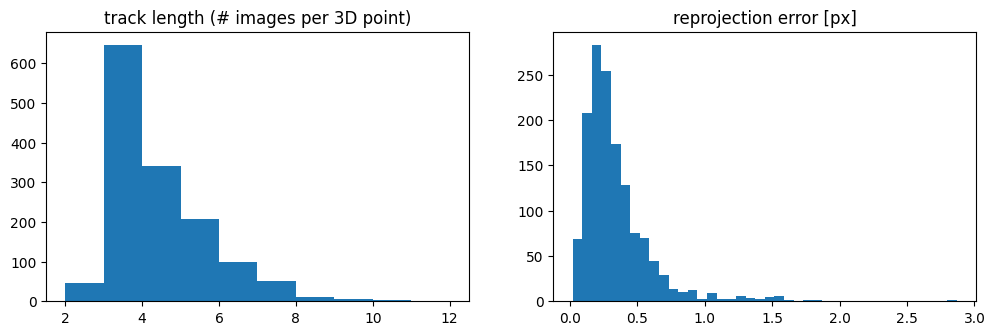

In [19]:
def qvec2rotmat(q):
    w, x, y, z = q
    return np.array([[1 - 2*y*y - 2*z*z, 2*x*y - 2*w*z, 2*x*z + 2*w*y],
                     [2*x*y + 2*w*z, 1 - 2*x*x - 2*z*z, 2*y*z - 2*w*x],
                     [2*x*z - 2*w*y, 2*y*z + 2*w*x, 1 - 2*x*x - 2*y*y]])

def read_model_txt(path):
    path = Path(path)
    pts, rgb, err, track_len = [], [], [], []
    for line in (path / "points3D.txt").read_text().splitlines():
        if line.startswith("#") or not line.strip(): continue
        v = line.split()
        pts.append([float(a) for a in v[1:4]]); rgb.append([int(a) for a in v[4:7]])
        err.append(float(v[7])); track_len.append((len(v) - 8) // 2)
    cams = {}
    lines = [l for l in (path / "images.txt").read_text().splitlines() if not l.startswith("#")]
    for header in lines[0::2]:
        v = header.split()
        if len(v) < 10: continue
        R = qvec2rotmat([float(a) for a in v[1:5]]); t = np.array([float(a) for a in v[5:8]])
        cams[v[9]] = (R, t)
    return np.array(pts), np.array(rgb), np.array(err), np.array(track_len), cams

P, RGB, ERR, TRACK, CAMS = read_model_txt(TXT)
print(f"{len(P)} points, {len(CAMS)} cameras, mean reprojection error {ERR.mean():.2f} px")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
axs[0].hist(TRACK, bins=range(2, TRACK.max() + 2)); axs[0].set_title("track length (# images per 3D point)")
axs[1].hist(ERR, bins=40); axs[1].set_title("reprojection error [px]")
plt.show()

In [20]:
def frustum(R, t, s=0.4, color="red", name=""):
    C = -R.T @ t
    c = np.array([[-1, -0.75, 1.5], [1, -0.75, 1.5], [1, 0.75, 1.5], [-1, 0.75, 1.5]]) * s
    w = (R.T @ c.T).T + C
    p = np.array([C, w[0], C, w[1], C, w[2], C, w[3], w[0], w[1], w[2], w[3], w[0]])
    return go.Scatter3d(x=p[:, 0], y=p[:, 1], z=p[:, 2], mode="lines", line=dict(color=color, width=3),
                        name=name, showlegend=False)

keep = np.linalg.norm(P - np.median(P, 0), axis=1) < np.percentile(np.linalg.norm(P - np.median(P, 0), axis=1), 97)
traces = [go.Scatter3d(x=P[keep, 0], y=P[keep, 1], z=P[keep, 2], mode="markers",
                       marker=dict(size=1.5, color=[f"rgb({r},{g},{b})" for r, g, b in RGB[keep]]), name="points")]
traces += [frustum(R, t, name=n) for n, (R, t) in CAMS.items()]
fig = go.Figure(traces)
fig.update_layout(scene=dict(aspectmode="data", camera=dict(up=dict(x=0, y=-1, z=0))), height=650,
                  title="COLMAP sparse model: 3D points + the 10 cameras")
fig.show()

(registered images, 3D points) after each snapshot: [(3, 267), (4, 313), (5, 343), (6, 708), (7, 992), (8, 1057), (9, 1191), (10, 1414)]


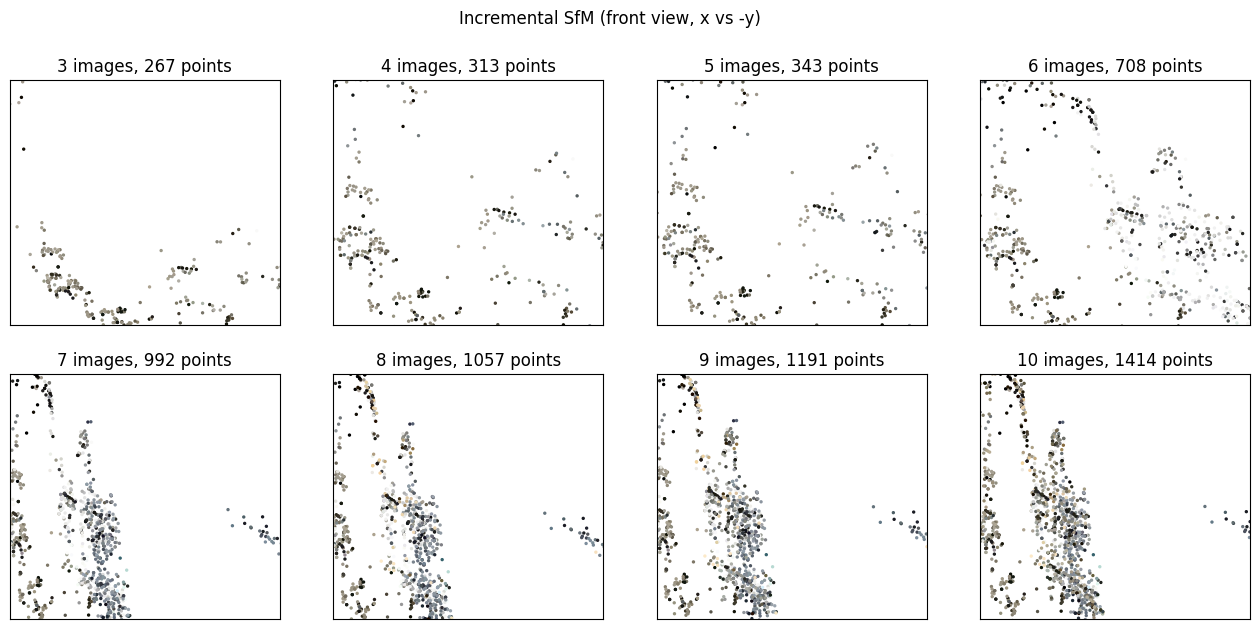

In [21]:
# Watch the reconstruction grow: one snapshot per newly registered image
snaps = sorted(SNAP.iterdir())
growth = []
for s in snaps:
    out = WS / "snap_txt" / s.name; out.mkdir(parents=True, exist_ok=True)
    subprocess.run([COLMAP, "model_converter", "--input_path", str(s), "--output_path", str(out),
                    "--output_type", "TXT"], capture_output=True)
    p, _, _, _, c = read_model_txt(out); growth.append((len(c), len(p)))
print("(registered images, 3D points) after each snapshot:", growth)

# keep only the snapshots of the final (successful) reconstruction: counts grow monotonically to the end
start = len(growth) - 1
while start > 0 and growth[start - 1][0] <= growth[start][0] and growth[start - 1][1] <= growth[start][1]:
    start -= 1
snaps, growth = snaps[start:], growth[start:]

cols = min(4, len(snaps)); rows_ = int(np.ceil(len(snaps) / cols))
fig, axs = plt.subplots(rows_, cols, figsize=(4 * cols, 3.5 * rows_))
for ax, s, (ni, npnt) in zip(np.ravel(axs), snaps, growth):
    p, rgb, _, _, c = read_model_txt(WS / "snap_txt" / s.name)
    ax.scatter(p[:, 0], -p[:, 1], s=2, c=rgb / 255); ax.set_title(f"{ni} images, {npnt} points")
    lo, hi = np.percentile(p, 3, axis=0), np.percentile(p, 97, axis=0)   # each snapshot has its own frame/scale
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(-hi[1], -lo[1]); ax.set_xticks([]); ax.set_yticks([])
for ax in np.ravel(axs)[len(snaps):]: ax.axis("off")
plt.suptitle("Incremental SfM (front view, x vs -y)"); plt.show()

## Step 5 (laptop with a CUDA GPU) · dense reconstruction

The sparse model only contains distinctive points. **Multi-view stereo** estimates a depth for (almost) every pixel and fuses the depth maps into a dense point cloud:

```
image_undistorter  ->  patch_match_stereo (CUDA only)  ->  stereo_fusion  ->  fused.ply
```

Run the cell below on the laptop. On Colab CPU it is skipped.

In [22]:
has_cuda = shutil.which("nvidia-smi") is not None and "CUDA" in subprocess.run(
    [COLMAP, "-h"], capture_output=True, text=True).stdout
if has_cuda:
    DENSE = WS / "dense"
    for cmd in [
        [COLMAP, "image_undistorter", "--image_path", IMAGES, "--input_path", MODEL, "--output_path", DENSE, "--max_image_size", "1200"],
        [COLMAP, "patch_match_stereo", "--workspace_path", DENSE],
        [COLMAP, "stereo_fusion", "--workspace_path", DENSE, "--output_path", DENSE / "fused.ply"],
    ]:
        print(" ".join(map(str, cmd))); subprocess.run(list(map(str, cmd)), check=True, capture_output=True)
    print("dense point cloud:", DENSE / "fused.ply")
else:
    print("No CUDA GPU here: skipping dense MVS (run this cell on the laptop).")

/usr/local/bin/colmap image_undistorter --image_path colmap_ws/images --input_path colmap_ws/sparse/0 --output_path colmap_ws/dense --max_image_size 1200
/usr/local/bin/colmap patch_match_stereo --workspace_path colmap_ws/dense
/usr/local/bin/colmap stereo_fusion --workspace_path colmap_ws/dense --output_path colmap_ws/dense/fused.ply
dense point cloud: colmap_ws/dense/fused.ply


### On the laptop: look at it in the GUI

```bash
colmap gui --database_path colmap_ws/database.db --image_path colmap_ws/images --import_path colmap_ws/sparse/0
```

(Or *File → Import model*.) Double-click a camera to see which points it observes.

**Takeaways**
* COLMAP = features → matching + RANSAC → incremental SfM (PnP + triangulation + BA). The same pieces as Notebooks 1–3.
* Output = cameras (intrinsics), images (poses), points3D (sparse map with tracks). **This is the map we localise against on Day 2.**

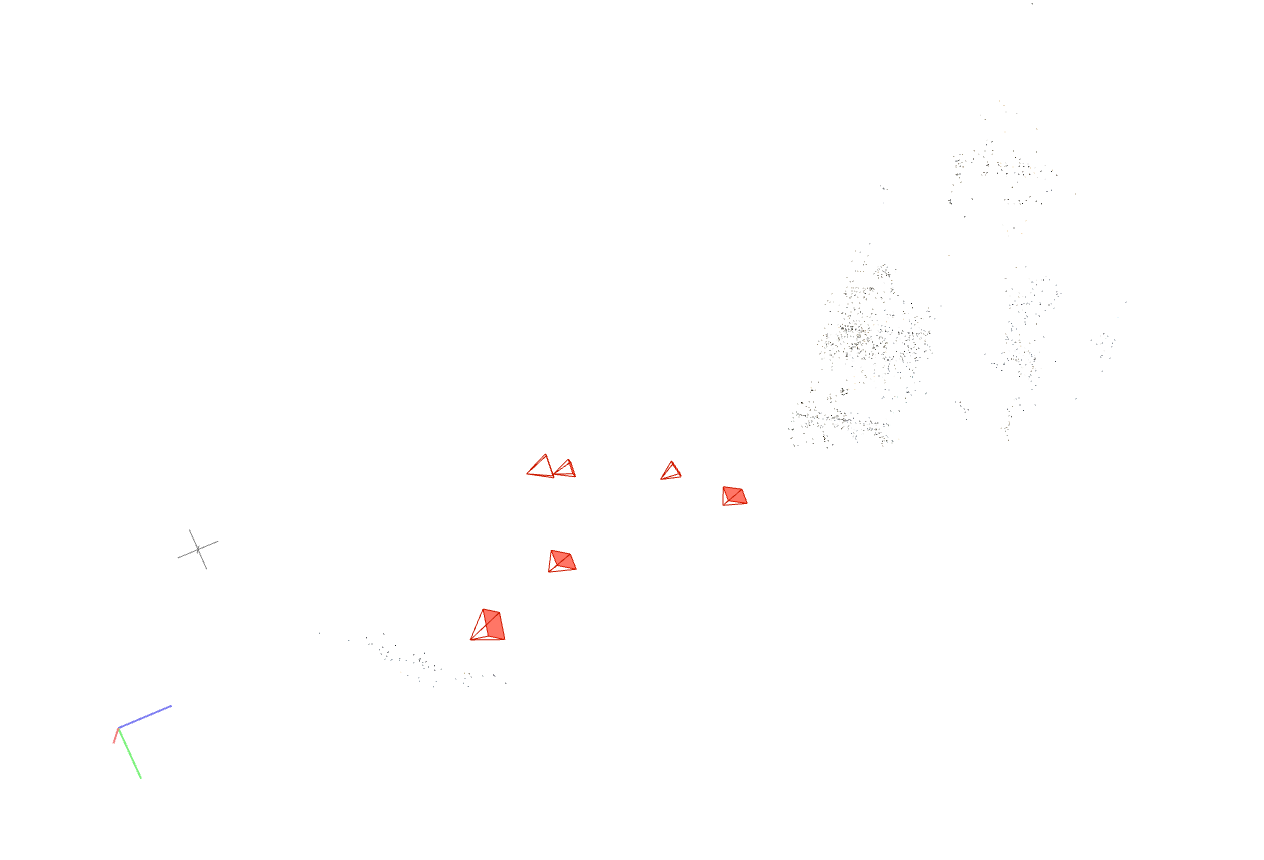